In [3]:
import torch
import torch.nn as nn
import numpy as np
import random
import json

from pathlib import Path
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Project directory
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

DATA_DIR = PROJECT_ROOT / "data"

# Load vocabulary
with open(DATA_DIR / "vocab.json", "r", encoding="utf-8") as f:
    word_to_id = json.load(f)

id_to_word = {
    idx: word for word, idx in word_to_id.items()
}

# Load tokenized datasets
token_data = torch.load(
    DATA_DIR / "token_ids.pt",
    weights_only=True
)

train_ids = token_data["train"]
val_ids = token_data["validation"]
test_ids = token_data["test"]

# Define required variables
VOCAB_SIZE = len(word_to_id)

PAD_ID = word_to_id["<pad>"]
UNK_ID = word_to_id["<unk>"]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)
print("Vocabulary size:", VOCAB_SIZE)
print("Training tokens:", len(train_ids))
print("Padding ID:", PAD_ID)
print("Unknown ID:", UNK_ID)

Device: cpu
Vocabulary size: 10000
Training tokens: 2051910
Padding ID: 0
Unknown ID: 1


In [4]:
EMBEDDING_DIM = 100
HIDDEN_DIM = 128
NUM_LAYERS = 1

model = LSTMLanguageModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS
).to(DEVICE)

total_params = sum(
    p.numel() for p in model.parameters()
)

print(model)
print(f"\nTotal parameters: {total_params:,}")

dummy_input = torch.randint(
    0, VOCAB_SIZE, (32, 32)
).to(DEVICE)

with torch.no_grad():
    dummy_output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

assert dummy_output.shape == (32, 32, VOCAB_SIZE)

print("\nLSTM forward pass successful!")

LSTMLanguageModel(
  (embedding): Embedding(10000, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=10000, bias=True)
)

Total parameters: 2,407,760
Input shape: torch.Size([32, 32])
Output shape: torch.Size([32, 32, 10000])

LSTM forward pass successful!


In [5]:
from torch.utils.data import Dataset, DataLoader

CONTEXT_LENGTH = 32
BATCH_SIZE = 32

class LanguageModelDataset(Dataset):

    def __init__(self, token_ids, context_length=32):
        self.tokens = torch.tensor(token_ids, dtype=torch.long)
        self.context_length = context_length

    def __len__(self):
        return (len(self.tokens) - 1) // self.context_length

    def __getitem__(self, idx):
        start = idx * self.context_length
        end = start + self.context_length

        x = self.tokens[start:end]
        y = self.tokens[start + 1:end + 1]

        return x, y


train_dataset = LanguageModelDataset(train_ids, CONTEXT_LENGTH)
val_dataset = LanguageModelDataset(val_ids, CONTEXT_LENGTH)
test_dataset = LanguageModelDataset(test_ids, CONTEXT_LENGTH)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 2004
Validation batches: 209
Test batches: 236


In [6]:
import torch.optim as optim

LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_ID
)

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)

Loss function: CrossEntropyLoss()
Optimizer: Adam


In [7]:
model.train()

x_batch, y_batch = next(iter(train_loader))

x_batch = x_batch.to(DEVICE)
y_batch = y_batch.to(DEVICE)

optimizer.zero_grad()

logits = model(x_batch)

loss = criterion(
    logits.reshape(-1, VOCAB_SIZE),
    y_batch.reshape(-1)
)

loss.backward()

torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1.0
)

optimizer.step()

print(f"Initial training loss: {loss.item():.4f}")
print(f"Initial perplexity: {torch.exp(loss).item():.2f}")
print("LSTM training step successful!")

Initial training loss: 9.2299
Initial perplexity: 10197.09
LSTM training step successful!


In [8]:
import time

# Reset model for reproducibility
torch.manual_seed(SEED)

model = LSTMLanguageModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

NUM_BENCHMARK_BATCHES = 20

model.train()

start_time = time.perf_counter()

for batch_idx, (x, y) in enumerate(train_loader):

    if batch_idx >= NUM_BENCHMARK_BATCHES:
        break

    x = x.to(DEVICE)
    y = y.to(DEVICE)

    optimizer.zero_grad()

    logits = model(x)

    loss = criterion(
        logits.reshape(-1, VOCAB_SIZE),
        y.reshape(-1)
    )

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

elapsed = time.perf_counter() - start_time

seconds_per_batch = elapsed / NUM_BENCHMARK_BATCHES
estimated_epoch_time = seconds_per_batch * len(train_loader)

print(f"Benchmark batches: {NUM_BENCHMARK_BATCHES}")
print(f"Total benchmark time: {elapsed:.2f} seconds")
print(f"Average time per batch: {seconds_per_batch:.3f} seconds")
print(f"Estimated time per epoch: {estimated_epoch_time / 60:.2f} minutes")
print(f"Estimated time for 5 epochs: {estimated_epoch_time * 5 / 60:.2f} minutes")

Benchmark batches: 20
Total benchmark time: 1.48 seconds
Average time per batch: 0.074 seconds
Estimated time per epoch: 2.48 minutes
Estimated time for 5 epochs: 12.39 minutes


In [9]:
import time
import math
import random
import numpy as np
from pathlib import Path

EPOCHS = 5
LEARNING_RATE = 0.001

# Reset random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Reset model after benchmarking
model = LSTMLanguageModel(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_ID
)

history = {
    "train_loss": [],
    "val_loss": [],
    "epoch_time": []
}

MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

print("LSTM reinitialized successfully!")
print("Training device:", DEVICE)

LSTM reinitialized successfully!
Training device: cpu


In [10]:
from tqdm.auto import tqdm

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0.0
    total_tokens = 0

    for x, y in tqdm(loader, desc="Training", leave=False):
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad()

        logits = model(x)

        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            y.reshape(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        num_tokens = (y != PAD_ID).sum().item()

        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens

    return total_loss / total_tokens


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for x, y in tqdm(loader, desc="Validation", leave=False):
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        logits = model(x)

        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            y.reshape(-1)
        )

        num_tokens = (y != PAD_ID).sum().item()

        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens

    return total_loss / total_tokens

In [11]:
best_val_loss = float("inf")
total_training_time = 0.0

for epoch in range(EPOCHS):

    start_time = time.perf_counter()

    train_loss = train_one_epoch(
        model, train_loader, optimizer, criterion
    )

    val_loss = evaluate(
        model, val_loader, criterion
    )

    epoch_time = time.perf_counter() - start_time
    total_training_time += epoch_time

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["epoch_time"].append(epoch_time)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val PPL: {math.exp(val_loss):.2f} | "
        f"Time: {epoch_time:.1f}s"
    )

    # Save the checkpoint with the best validation loss
    if val_loss < best_val_loss:
        best_val_loss = val_loss

        torch.save({
            "model_state_dict": model.state_dict(),
            "epoch": epoch + 1,
            "val_loss": val_loss,
            "config": {
                "vocab_size": VOCAB_SIZE,
                "embedding_dim": EMBEDDING_DIM,
                "hidden_dim": HIDDEN_DIM,
                "num_layers": NUM_LAYERS
            }
        }, MODELS_DIR / "lstm_best.pt")

print("\nLSTM training completed!")
print(f"Total training time: {total_training_time / 60:.2f} minutes")
print(f"Best validation perplexity: {math.exp(best_val_loss):.2f}")

Training:   0%|          | 0/2004 [00:00<?, ?it/s]

Validation:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 1/5 | Train Loss: 5.8480 | Val Loss: 5.3647 | Val PPL: 213.74 | Time: 327.1s


Training:   0%|          | 0/2004 [00:00<?, ?it/s]

Validation:   0%|          | 0/209 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 4/5 | Train Loss: 4.9687 | Val Loss: 4.9997 | Val PPL: 148.36 | Time: 285.6s


Training:   0%|          | 0/2004 [00:00<?, ?it/s]

Validation:   0%|          | 0/209 [00:00<?, ?it/s]

Epoch 5/5 | Train Loss: 4.8684 | Val Loss: 4.9548 | Val PPL: 141.85 | Time: 283.6s

LSTM training completed!
Total training time: 24.74 minutes
Best validation perplexity: 141.85


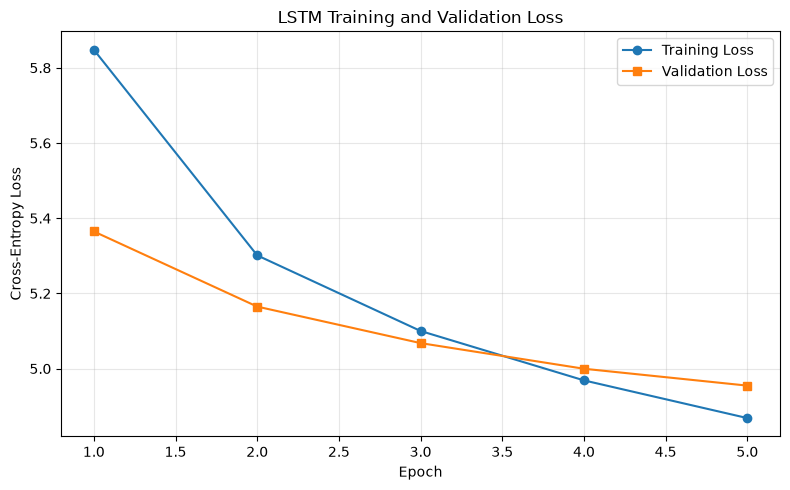

In [12]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "lstm_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
checkpoint = torch.load(
    MODELS_DIR / "lstm_best.pt",
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Best LSTM model loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print(f"Best validation loss: {checkpoint['val_loss']:.4f}")

Best LSTM model loaded successfully!
Best epoch: 5
Best validation loss: 4.9548


In [14]:
import math
import time

start_time = time.perf_counter()

test_loss = evaluate(
    model,
    test_loader,
    criterion
)

test_time = time.perf_counter() - start_time
test_ppl = math.exp(test_loss)

print(f"Test cross-entropy: {test_loss:.4f}")
print(f"Test perplexity: {test_ppl:.2f}")
print(f"Test evaluation time: {test_time:.2f} seconds")

Validation:   0%|          | 0/236 [00:00<?, ?it/s]

Test cross-entropy: 4.8790
Test perplexity: 131.49
Test evaluation time: 6.13 seconds


In [15]:
@torch.no_grad()
def generate_lstm(
    model,
    prompt,
    max_new_tokens=30,
    temperature=1.0,
    top_k=20,
    seed=42
):
    model.eval()

    generator = torch.Generator(device=DEVICE)
    generator.manual_seed(seed)

    tokens = prompt.lower().split()

    generated_ids = [
        word_to_id.get(token, UNK_ID)
        for token in tokens
    ]

    for _ in range(max_new_tokens):

        # Use the last 32 tokens
        input_ids = generated_ids[-CONTEXT_LENGTH:]

        x = torch.tensor(
            [input_ids],
            dtype=torch.long,
            device=DEVICE
        )

        # Forward pass
        logits = model(x)

        # Get next-token logits
        next_logits = logits[0, -1, :].clone()

        # Exclude padding
        next_logits[PAD_ID] = float("-inf")

        # Temperature scaling
        next_logits = next_logits / temperature

        # Top-k filtering
        if top_k is not None:
            values, indices = torch.topk(
                next_logits,
                k=top_k
            )

            filtered_logits = torch.full_like(
                next_logits,
                float("-inf")
            )

            filtered_logits[indices] = values
            next_logits = filtered_logits

        # Convert logits into probabilities
        probs = torch.softmax(next_logits, dim=-1)

        # Sample next token
        next_id = torch.multinomial(
            probs,
            num_samples=1,
            generator=generator
        ).item()

        generated_ids.append(next_id)

    return " ".join(
        id_to_word[idx] for idx in generated_ids
    )

In [16]:
prompts = [
    "the game",
    "in the",
    "the history of"
]

for prompt in prompts:

    generated_text = generate_lstm(
        model=model,
        prompt=prompt,
        max_new_tokens=30,
        temperature=1.0,
        top_k=20,
        seed=42
    )

    print("=" * 60)
    print("PROMPT:", prompt)
    print("GENERATED:")
    print(generated_text)
    print()

PROMPT: the game
GENERATED:
the game , " it was never thought that her " was a <unk> . " = = = = = <unk> and career = = = " the <unk> , '

PROMPT: in the
GENERATED:
in the <unk> . it was also to get at the end of <unk> . the <unk> was a <unk> in <unk> , which he had to <unk> the series , but

PROMPT: the history of
GENERATED:
the history of the first season of <unk> to the end of the 20th century . the <unk> was a <unk> in <unk> , which he had to <unk> the series , but



In [17]:
import json
import math

RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

prompts = [
    "the game",
    "in the",
    "the history of"
]

generated_samples = {}

for prompt in prompts:
    generated_samples[prompt] = generate_lstm(
        model=model,
        prompt=prompt,
        max_new_tokens=30,
        temperature=1.0,
        top_k=20,
        seed=42
    )

lstm_results = {
    "model": "LSTM",
    "embedding_dim": EMBEDDING_DIM,
    "hidden_dim": HIDDEN_DIM,
    "num_layers": NUM_LAYERS,
    "parameters": total_params,
    "epochs": EPOCHS,
    "best_epoch": checkpoint["epoch"],
    "best_val_loss": checkpoint["val_loss"],
    "best_val_perplexity": math.exp(checkpoint["val_loss"]),
    "test_loss": test_loss,
    "test_perplexity": test_ppl,
    "test_evaluation_time_seconds": test_time,
    "training_time_seconds": total_training_time,
    "history": history,
    "generated_samples": generated_samples
}

with open(
    RESULTS_DIR / "lstm_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(lstm_results, f, indent=2, ensure_ascii=False)

print("LSTM results saved successfully!")
print("File:", RESULTS_DIR / "lstm_results.json")

LSTM results saved successfully!
File: c:\Users\User\NUS\DSA NLP\DSA4213_Assignment1\results\lstm_results.json
